# **Assignment 12: Autoencoders and Generative AI**

## Author: Mohammad Mehdi Zare, Mohammad Ali Olama

#Load Libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(color_codes=True)
import pandas as pd
import numpy as np

import io
import os
import copy
import pdb
from keras.models import Sequential
from keras import callbacks
import keras
import tensorflow as tf
from sklearn.metrics import f1_score
from tensorflow.keras import initializers
from keras.regularizers import l2,l1,l1_l2
from keras.layers import Dense, Input, Dropout, Conv2D, AveragePooling2D, MaxPooling2D, Flatten, Reshape, Conv2DTranspose, LeakyReLU, BatchNormalization

%matplotlib inline
sns.set(color_codes=True)

In [2]:

#Check the version of TensorFlow you are using
print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.17.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# Diable warnings about max_itr not reached etc.!
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

#Dataset

The Fashion MNIST dataset is a large freely available database of fashion images. It contains 70,000 28x28 grayscale images of fashion products from 10 categories from a dataset of Zalando article images, with 7,000 images per category. The training set consists of 60,000 images and the test set consists of 10,000 images.

Each training and test example is assigned to one of the following labels:

Label	Description
* 0	T-shirt/top
* 1	Trouser
* 2	Pullover
* 3	Dress
* 4	Coat
* 5	Sandal
* 6	Shirt
* 7	Sneaker
* 8	Bag
* 9	Ankle boot

In [4]:
fashion_mnist = keras.datasets.fashion_mnist
(X_train,y_train),(X_test,y_test) = fashion_mnist.load_data()

print(f'size of training set: {X_train.shape}')
print(f'size of test set: {X_test.shape}')

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 85us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
size of training set: (60000, 28, 28)
size of test set: (10000, 28, 28)


Now let's take a look at sample images.

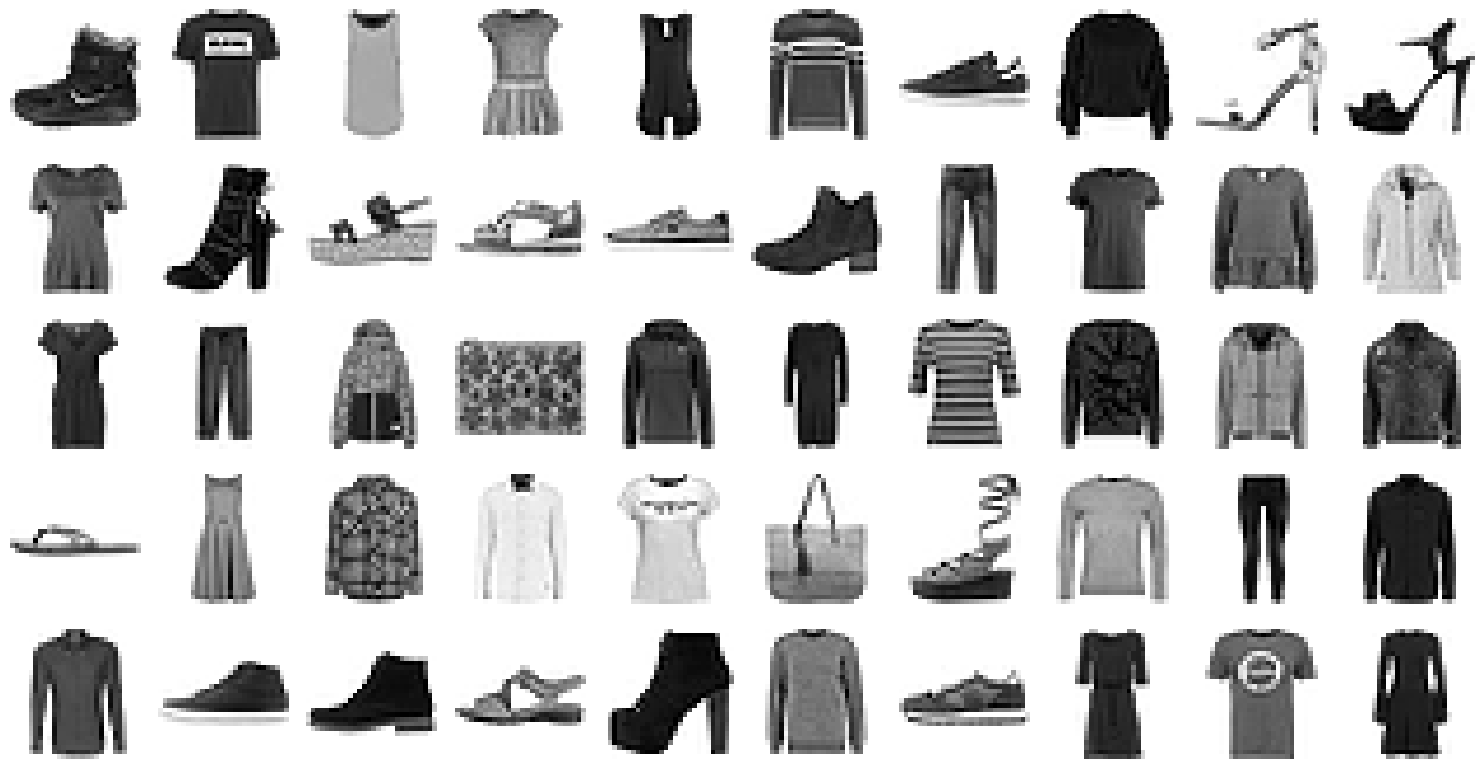

In [5]:

plt.figure(figsize=(15,8))
for i in range(50):
    plt.subplot(5,10,i+1)
    plt.imshow(X_train[i].reshape((28,28)),cmap='binary')
    plt.axis("off")
plt.tight_layout()

As you can see and as menstioned earlier, all classes have almost equal amount of samples.

Since we want to use Keras  API for this homework and the Keras models need to receive labels in the one-hot-encoding format, we do so in the cell below.

In [6]:
from sklearn.preprocessing import OneHotEncoder,LabelBinarizer
enc = LabelBinarizer()
y_train = enc.fit_transform(y_train)
y_test = enc.fit_transform(y_test)

In [7]:
y_train.shape

(60000, 10)

In [8]:
y_train[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

Fashion Mnist is a well processed dataset and do not need any further cleaning so we only scladed all images to have pixels value between 0 and 1.

In [9]:
X_train = X_train/255.
X_test = X_test/255.

#Utilities

The next three cells are some useful functions throughout the assignment.

In [10]:
#Early stopping
early_stopping = callbacks.EarlyStopping(
    min_delta=0.001,          # minimium amount of change to be considered an improvement
    patience=5,              # number of epochs to wait before deciding there is no significant improvement in training
    restore_best_weights=True,
)

In [11]:
#@title plot_history
def plot_history(history,plot_type: str='loss'):
  hist_df = pd.DataFrame(history.history)
  plt.figure(figsize=(20,8))
  colors = []
  columns_to_plot = []
  labels = []
  for col_name in hist_df.columns:

    # Define colors
    if 'val' in col_name:
      validation = True
      color_base = 'r'
      label_base = 'Validation'
    else:
      validation = False
      color_base = 'b'
      label_base = 'Training'

    if plot_type == 'loss':
      if 'loss' in col_name:
        labels.append(label_base)
        columns_to_plot.append(col_name)
        colors.append(color_base)
    else:
      if 'loss' in col_name:
        continue
      if 'recall' in col_name:
        color = color_base + '--'
        label = label_base + 'Recall'
      else:
        color = color_base
        label = label_base + 'Precision'

      labels.append(label)
      columns_to_plot.append(col_name)
      colors.append(color)



  for itr in range(0,len(columns_to_plot)):
    plt.plot(hist_df.loc[:, [columns_to_plot[itr]]], colors[itr], label=labels[itr],lw=4)

  plt.ylabel(plot_type)
  plt.xlabel('Epochs')
  plt.legend(loc="best")

  plt.show()

# Part1: Autoencoder

Given the model, the next function plots the constructed images.

In [12]:
def plot_sample_output(model,input_dataset=X_test):
  fig, ax = plt.subplots(nrows=2, ncols=8, figsize=(24,6))
  for i in range(0,8):
    # convert to unsigned integers
    image = input_dataset[i,:,:]
    pred = model.predict(np.expand_dims(image, axis=0))

    # plot image
    ax[0,i].imshow(image, cmap='binary')
    ax[0,i].axis('off')

    ax[1,i].imshow(pred.reshape(input_dataset.shape[1:]), cmap='binary')
    ax[1,i].axis('off')

In [13]:
input_size = X_train[0].shape
latent_space_dim = 50

##Dense Autoencoder

Dense Autoencoder is an autoencoder that uses MLP as its encoder and decoder. We build a model with three dense layers for each encoder and decoder.

Input and output shapes are the same, and it is equal to the image shape, which is 28*28.

In [14]:
# The encoder part
model = Sequential()
model.add(keras.layers.Flatten(input_shape=input_size))
model.add(Dense(150, activation="relu"))
model.add(Dense(80, activation="relu"))

#output of this layer is latent variable
model.add(Dense(latent_space_dim, activation="relu"))

In [15]:
# The decoder part
model.add(Dense(80, activation="relu"))
model.add(Dense(150, activation="relu"))
model.add(Dense(X_train.shape[1] * X_train.shape[2] , activation="sigmoid"))
model.add(Reshape(X_train.shape[1:]))

We use MSE loss and adam optimizer with initial learning rate of 0.001, then compile the model:

In [16]:
from tensorflow.keras.losses import MeanSquaredError
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001,beta_1=0.95),
              loss=MeanSquaredError(),
             )

As you can see in the model summary below, as the image goes through the model, the features get smaller in encoder part, then gets bigger in decoder part to match the size of the original image. Also, the model is symmetric.

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 150)                 │         117,750 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 80)                  │          12,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 50)                  │           4,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 80)                  │           4,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 150)                 │          12,150 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 784)                 │         118,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 28, 28)              │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 268,494 (1.02 MB)

 Trainable params: 268,494 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

Let's train the model:

In [18]:
history = model.fit(
      x=X_train,
      y=X_train,
      validation_data=(X_test,X_test),
      verbose=1,
      epochs=40,
      batch_size=128,
)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 0.0627 - val_loss: 0.0213
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0201 - val_loss: 0.0179
Epoch 3/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0173 - val_loss: 0.0162
Epoch 4/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0158 - val_loss: 0.0150
Epoch 5/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0147 - val_loss: 0.0142
Epoch 6/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0138 - val_loss: 0.0134
Epoch 7/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0132 - val_loss: 0.0129
Epoch 8/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0127 - val_loss: 0.0124
Epoch 9/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0122 - val_loss: 0.0123
Epoch 10/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0119 - val_loss: 0.0117
Epoch 11/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0116 - val_loss: 0.0115
Epoch 12/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/ste

Plot below show how the loss changes during training phase:

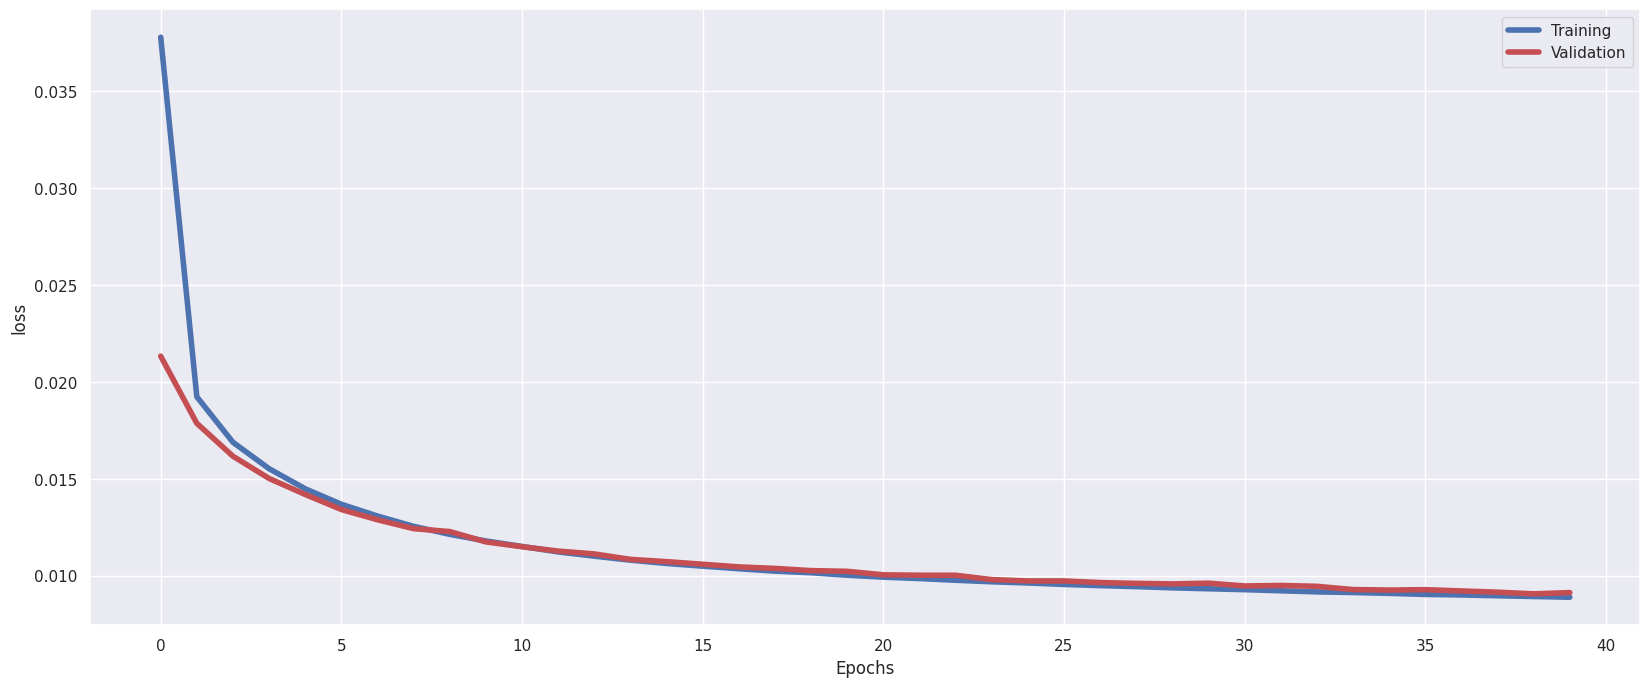

In [19]:
plot_history(history,plot_type='loss')

The image below shows the original images (inputs) and their constructed image by our trained model. as you can see, the result is pretty good. We can see that the model can recreate the overall shape of the clothes but cannot reconstruct the details, which is evident in the last image of a blouse.

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step  
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


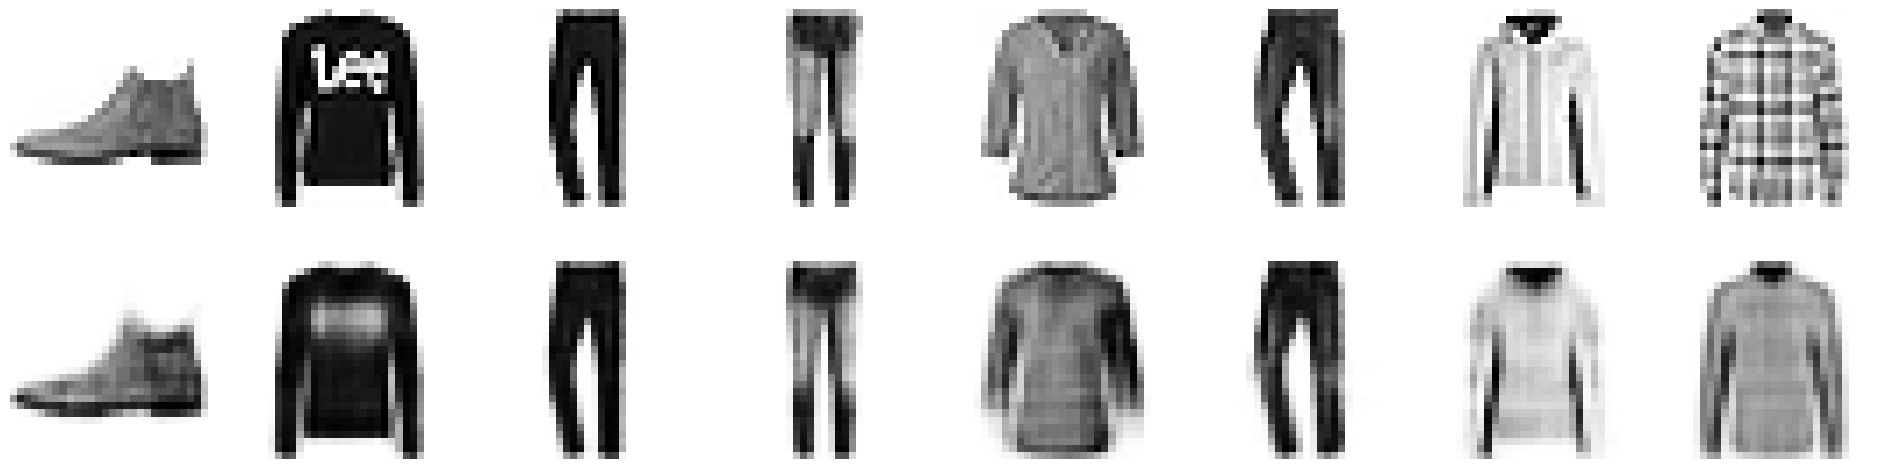

In [20]:
plot_sample_output(model)

To mitigate the problem of dense autoencoder that we mentioned, and since our inputs are images, we will use CNN architecture for the encoder and decoder model in the next section.

## Convoltuional AutoEncoder


As we said, we use CNN for our model. `Conv2D` down sample features and `Conv2DTranspose` layers are responsible for upsampling.

In [21]:
def CNN_autoencoder():
  model = Sequential()

  # Encoder
  model.add(Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu",input_shape=(28,28,1)))
  model.add(MaxPooling2D(pool_size=2, padding="same"))
  model.add(Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"))
  model.add(MaxPooling2D(pool_size=2, padding="same"))
  model.add(Conv2DTranspose(32, kernel_size=(3, 3), strides=2, padding="same",activation="relu"))
  model.add(Conv2DTranspose(1, kernel_size=(3, 3), strides=2, padding="same",activation="sigmoid"))
  model.add(Reshape([28, 28]))

  return model

In [22]:
model = CNN_autoencoder()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01,beta_1=0.95),
              loss='binary_crossentropy', #MeanSquaredError()
             )

In [23]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 14, 14, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 28, 28, 1)           │             289 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_1 (Reshape)                  │ (None, 28, 28)              │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 37,569 (146.75 KB)

 Trainable params: 37,569 (146.75 KB)

 Non-trainable params: 0 (0.00 B)


Since the network is relatively large and each epoch takes a long time, we only train the model for 10 epochs. Although this training is limited
The results are acceptable.

In [24]:
history = model.fit(
      x=X_train,
      y=X_train,
      validation_data=(X_test,X_test),
      verbose=1,
      epochs=40,
      batch_size=256,
)

Epoch 1/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - loss: 0.3409 - val_loss: 0.2663
Epoch 2/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.2620 - val_loss: 0.2599
Epoch 3/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.2573 - val_loss: 0.2575
Epoch 4/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.2552 - val_loss: 0.2561
Epoch 5/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - loss: 0.2538 - val_loss: 0.2550
Epoch 6/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2530 - val_loss: 0.2545
Epoch 7/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.2521 - val_loss: 0.2542
Epoch 8/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.2520 - val_loss: 0.2538
Epoch 9/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.2510 - val_loss: 0.2539
Epoch 10/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.2515 - val_loss: 0.2532
Epoch 11/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.2511 - val_loss: 0.2534
Epoch 12/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 5

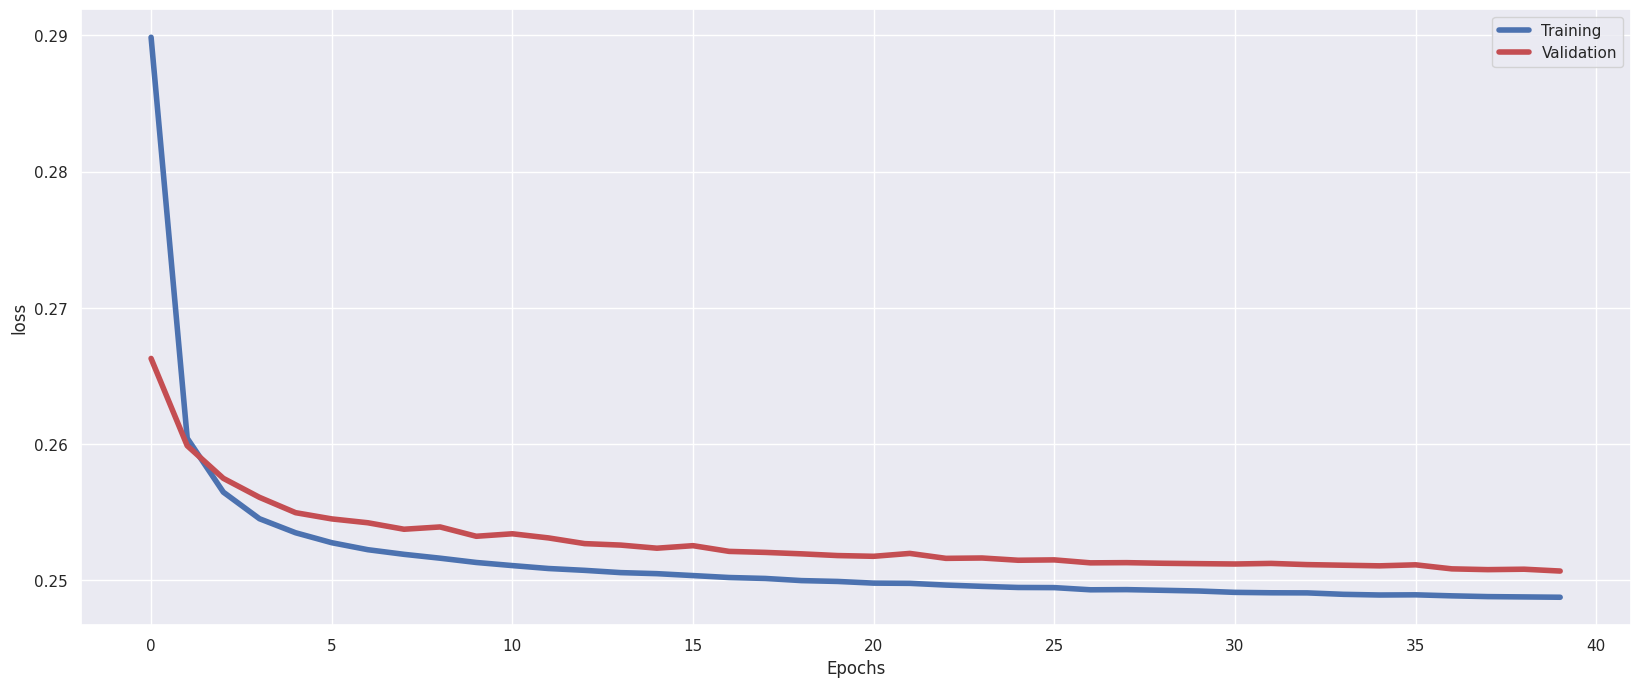

In [25]:
plot_history(history,plot_type='loss')

Again the result is shown below and as you can see that this time CNNs are care more about the details.

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


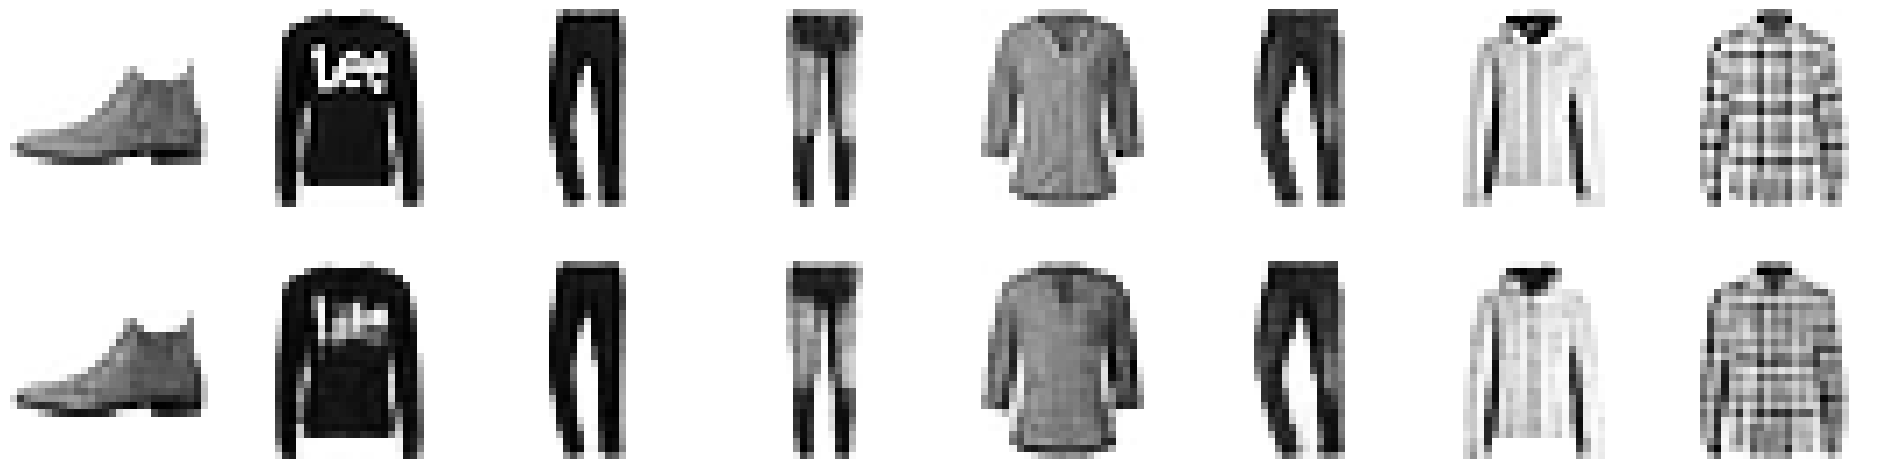

In [26]:
plot_sample_output(model)

## Denoising Autoencoders
To have denoising autoencoders,
we add noise to input images, then in the train loop, we use the noisy image as input and the original images as output. The model is supposed to reconstruct the original image from noisy input.

This way, the model learns to detect the important features even in noisy images.

In [27]:
def add_noise(images, noise_factor = 0.2):

    noisy_images = np.clip(images + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=images.shape) , 0.0, 1.0)

    return noisy_images

We add noise to the input image by adding images with the output of `np.random.normal`. This function draws random samples from a normal distribution (mean =0, std = 1). Since our pixels must be in [0,1], we then clip the value of noisy image pixels to ensure they are still between 0 and 1.

In [28]:
# Create a copy of the data with added noise
noisy_train_data = add_noise(X_train)
noisy_test_data = add_noise(X_test)

Here we train our model using the noisy image but note that the output must be the original images without noise.

In [29]:
model = CNN_autoencoder()
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01,beta_1=0.95),
              loss='binary_crossentropy', #MeanSquaredError()
             )

history = model.fit(
      x=noisy_train_data,
      y=X_train,
      validation_data=(noisy_test_data,X_test),
      verbose=1,
      epochs=40,
      batch_size=128,
)

Epoch 1/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 10ms/step - loss: 0.3315 - val_loss: 0.2762
Epoch 2/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.2732 - val_loss: 0.2721
Epoch 3/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.2689 - val_loss: 0.2706
Epoch 4/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.2685 - val_loss: 0.2699
Epoch 5/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2670 - val_loss: 0.2693
Epoch 6/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.2668 - val_loss: 0.2691
Epoch 7/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.2670 - val_loss: 0.2687
Epoch 8/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.2661 - val_loss: 0.2684
Epoch 9/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.2658 - val_loss: 0.2680
Epoch 10/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2658 - val_loss: 0.2681
Epoch 11/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.2658 - val_loss: 0.2678
Epoch 12/40
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/st

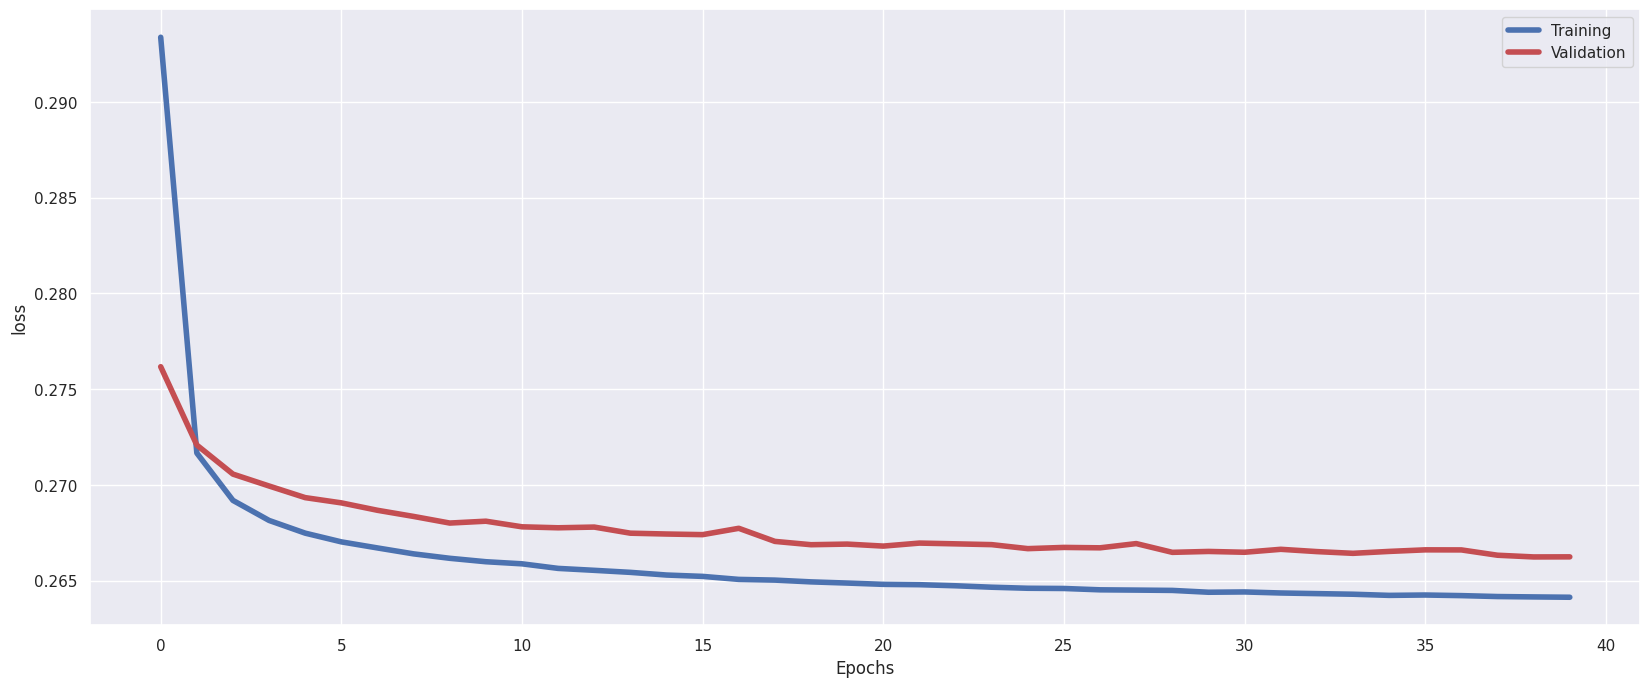

In [30]:
plot_history(history,plot_type='loss')

As you can see from either the history of loss and the input/output images that the model reconstructed, our model did a well enough work. It can successfully reconstruct images and mitigate noise, despite the noisy inputs.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


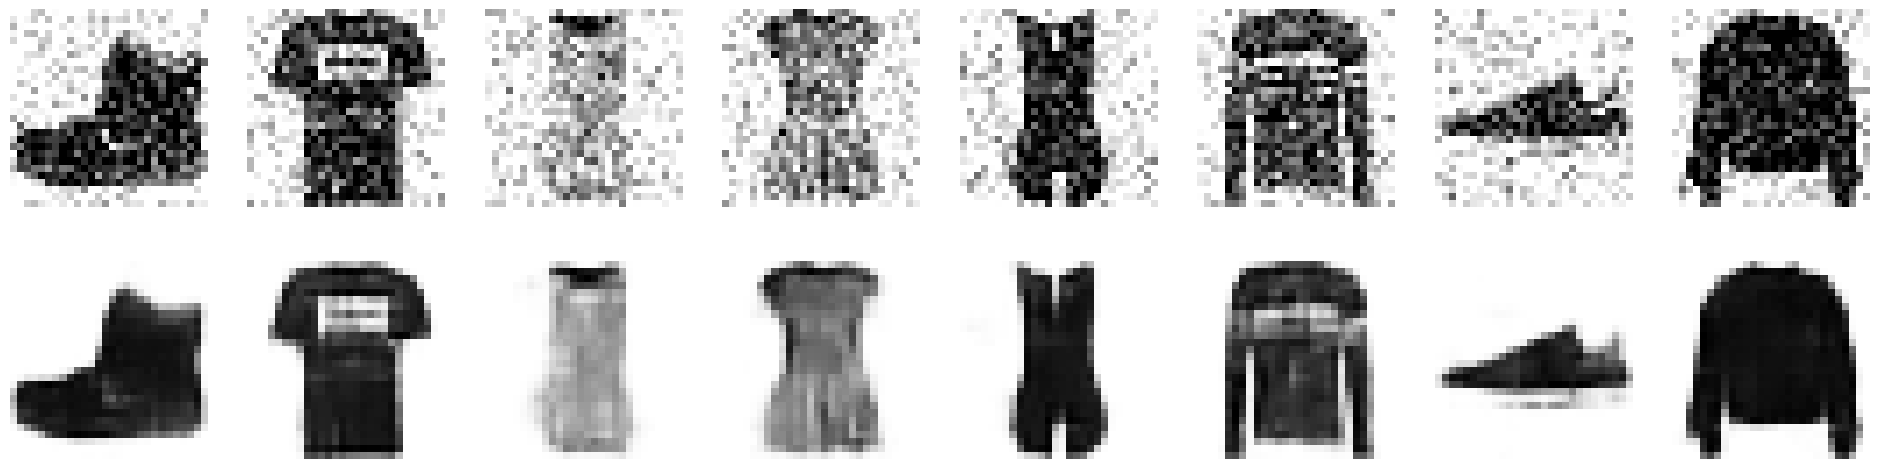

In [31]:
plot_sample_output(model,input_dataset=noisy_train_data)

# OPEN AI API

OPENAI's api is not free, It requires to buy credits. So the following code will generate an error, however if you have a valid api key with credits, it will work!

In [32]:
# !pip install openai

# import openai
# from openai import OpenAI
# import os
# from gtts import gTTS
# from playsound import playsound
# import matplotlib.pyplot as plt
# import matplotlib.image as mpimg
# from pathlib import Path

# client = OpenAI(api_key = "YOUR_API_KEY")



# #  Image generation
# image_prompt = "a man reading a sci-fi book in a coffeeshop in old Iran."


# response = client.images.generate(
#     model="dall-e-3",
#     prompt=image_prompt,
#     size="1024x1024",
#     quality="standard",
#     n=1,
# )

# print(response.data[0].url)
# image_url = response['data'][0]['url']

# # Download and display the image
# !wget {image_url} -O generated_image.png
# img = mpimg.imread('generated_image.png')
# plt.imshow(img)
# plt.axis('off')
# plt.show()




# # 2. Generate text using the Chat Completion API
# completion = client.chat.completions.create(
#     model="gpt-3.5-turbo",
#     messages=[
#         {"role": "developer",
#          "content": "You are a helpful assistant."
#          },
#         {
#             "role": "user",
#             "content": "Explain the importance of fast language models."
#         }
#     ]
# )

# print(completion.choices[0].message)


# # 3. Convert text to speech
# text = "This line imports the os module, which provides functions to interact with the operating system, including setting environment variables."
# speech_file_path = Path("speech.mp3").parent
# response = client.audio.speech.create(
#     model="tts-1",
#     voice="alloy",
#     input="Today is a wonderful day to build something people love!",
# )
# response.stream_to_file(speech_file_path)

As I have mentioned, the above cell won't work unless you have an api_key with paid subscription (Which We don't possess currently!)

But to demostrate the power of Genarative Ai, We will use Groq AI (From twitter) to generate a text!

In [34]:
# THIS CELL IS COMPLETELY ADOPTED FROM A SAMPLE IN https://console.groq.com/docs/text-chat

!pip install groq

from groq import Groq

client = Groq(api_key = "YOUR_GROQ_API_KEY")

chat_completion = client.chat.completions.create(
    #
    # Required parameters
    #
    messages=[
        # Set an optional system message. This sets the behavior of the
        # assistant and can be used to provide specific instructions for
        # how it should behave throughout the conversation.
        {
            "role": "system",
            "content": "you are a helpful assistant."
        },
        # Set a user message for the assistant to respond to.
        {
            "role": "user",
            "content": "Explain the importance of fast language models",
        }
    ],

    # The language model which will generate the completion.
    model="llama-3.3-70b-versatile",

    #
    # Optional parameters
    #

    # Controls randomness: lowering results in less random completions.
    # As the temperature approaches zero, the model will become deterministic
    # and repetitive.
    temperature=0.5,

    # The maximum number of tokens to generate. Requests can use up to
    # 32,768 tokens shared between prompt and completion.
    max_tokens=1024,

    # Controls diversity via nucleus sampling: 0.5 means half of all
    # likelihood-weighted options are considered.
    top_p=1,

    # A stop sequence is a predefined or user-specified text string that
    # signals an AI to stop generating content, ensuring its responses
    # remain focused and concise. Examples include punctuation marks and
    # markers like "[end]".
    stop=None,

    # If set, partial message deltas will be sent.
    stream=False,
)

# Print the completion returned by the LLM.
print(chat_completion.choices[0].message.content)

Fast language models are crucial in today's technology landscape, and their importance can be understood from several perspectives:

1. **Efficient Processing**: Fast language models can process and analyze vast amounts of text data quickly, enabling applications to respond rapidly to user inputs. This efficiency is essential for real-time applications, such as chatbots, virtual assistants, and language translation software.
2. **Improved User Experience**: Quick response times provided by fast language models enhance the overall user experience. Users can interact with language-based systems more naturally, without experiencing frustrating delays or waiting times.
3. **Increased Productivity**: By automating tasks that involve text analysis, such as data extraction, summarization, and sentiment analysis, fast language models can significantly increase productivity in various industries, including customer service, marketing, and research.
4. **Scalability**: Fast language models can h